In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("student_data.csv")

In [3]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:
df.shape

(395, 33)

In [5]:
df.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='object')

In [6]:
df.isnull().sum()

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

In [8]:
df.describe()

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


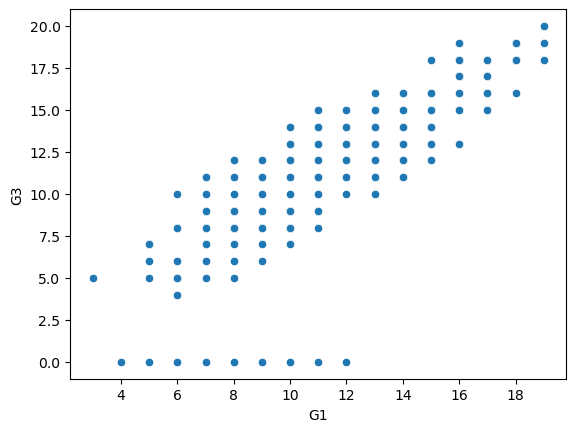

In [9]:
sns.scatterplot(data = df, x = "G1",y = "G3")
plt.show()

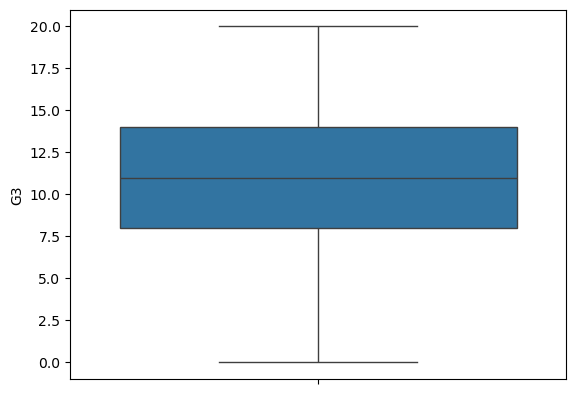

In [10]:
sns.boxplot(df["G3"])
plt.show()

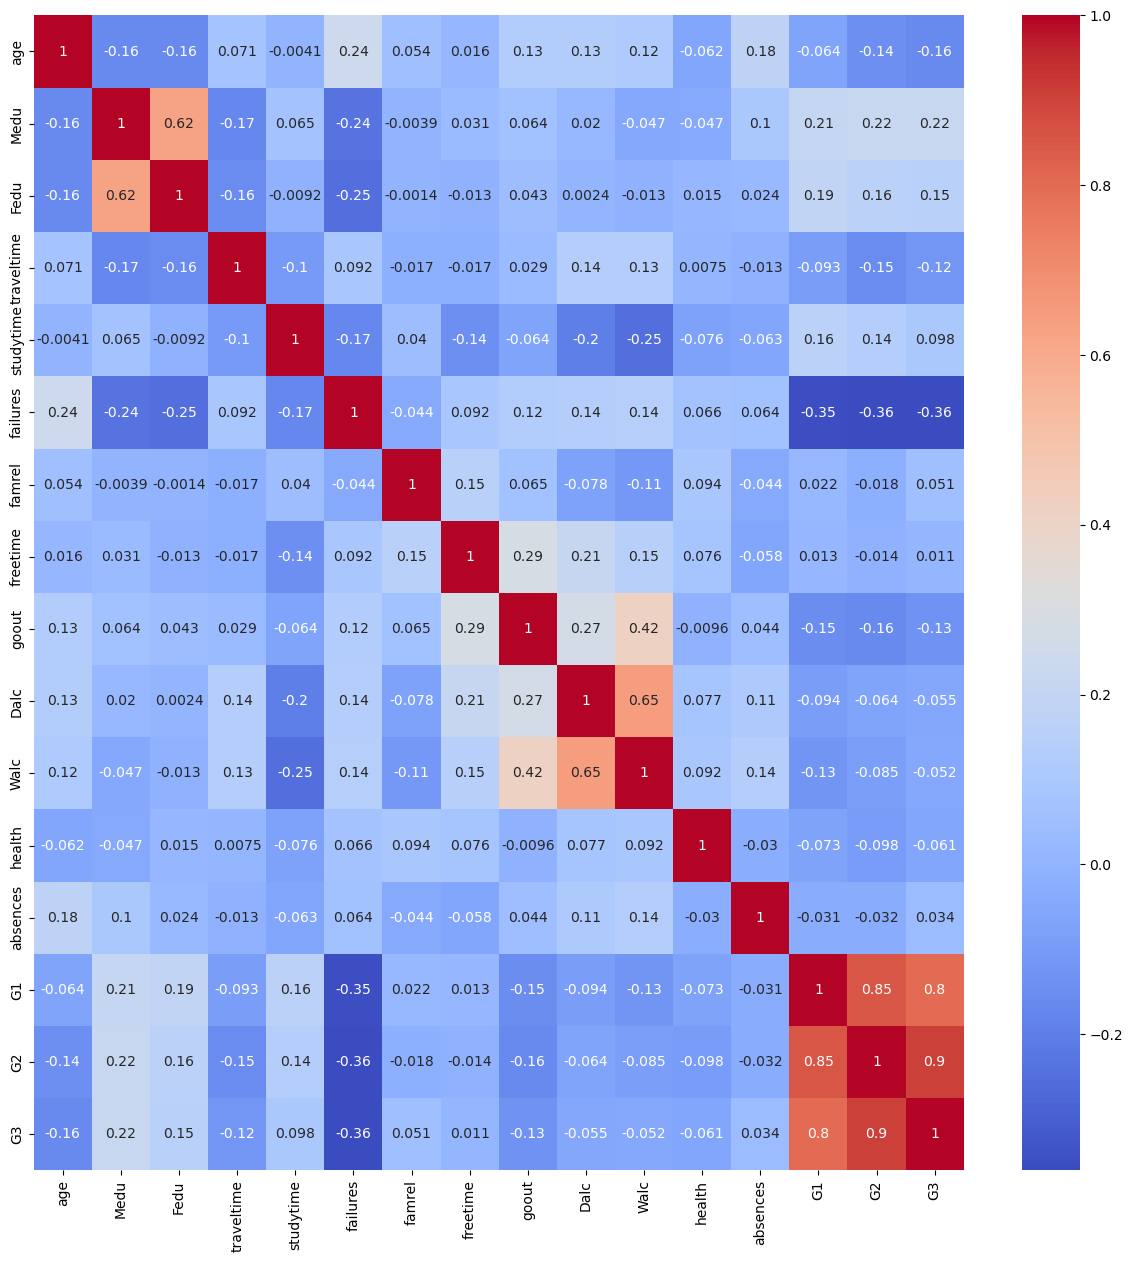

In [11]:
plt.figure(figsize = (15,15))
sns.heatmap(df.corr(numeric_only = True), annot = True, cmap = "coolwarm")
plt.show()

In [12]:
objects_columns = df.select_dtypes("O")

In [13]:
for i in objects_columns.columns:
    print(df[i].value_counts())

school
GP    349
MS     46
Name: count, dtype: int64
sex
F    208
M    187
Name: count, dtype: int64
address
U    307
R     88
Name: count, dtype: int64
famsize
GT3    281
LE3    114
Name: count, dtype: int64
Pstatus
T    354
A     41
Name: count, dtype: int64
Mjob
other       141
services    103
at_home      59
teacher      58
health       34
Name: count, dtype: int64
Fjob
other       217
services    111
teacher      29
at_home      20
health       18
Name: count, dtype: int64
reason
course        145
home          109
reputation    105
other          36
Name: count, dtype: int64
guardian
mother    273
father     90
other      32
Name: count, dtype: int64
schoolsup
no     344
yes     51
Name: count, dtype: int64
famsup
yes    242
no     153
Name: count, dtype: int64
paid
no     214
yes    181
Name: count, dtype: int64
activities
yes    201
no     194
Name: count, dtype: int64
nursery
yes    314
no      81
Name: count, dtype: int64
higher
yes    375
no      20
Name: count, dtype: int64

In [14]:
X = df.drop("G3", axis = 1)
y = df["G3"]

In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state=42)

In [16]:
cat_cols = df.select_dtypes("object").columns.to_list()

In [18]:
cat_cols

['school',
 'sex',
 'address',
 'famsize',
 'Pstatus',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic']

In [17]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [19]:
transformer = ColumnTransformer(
    transformers = [
        ("onehot",OneHotEncoder(drop="first",handle_unknown="ignore"),cat_cols)
    ], remainder= "passthrough" 
)

In [20]:
X_train = transformer.fit_transform(X_train)
X_test = transformer.transform(X_test)

In [21]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [23]:
from sklearn.linear_model import LinearRegression, Ridge,RidgeCV,Lasso,LassoCV,ElasticNet,ElasticNetCV
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error,mean_squared_error


model_defs = {
    "Linear Regression": LinearRegression(),
    "Ridge" : Ridge(),
    "RidgeCV": RidgeCV(),
    "Lasso": Lasso(),
    "LassoCV": LassoCV(),
    "ElasticNet": ElasticNet(),
    "ElasticNetCV": ElasticNetCV(),
    "SVR": SVR(),
    "KNeighbor": KNeighborsRegressor(),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(random_state=42),
    "AdaBoost Regressor": AdaBoostRegressor(random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "XGB Regressor": XGBRegressor(random_state=42),
    "LGBM Regressor": LGBMRegressor(random_state=42),
}

fitted_models = {}
results = []

for name, estimator in model_defs.items():
    estimator.fit(X_train_scaled,y_train)
    y_pred = estimator.predict(X_test_scaled)

    fitted_models[name] = estimator
    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test,y_pred),
        "MAE": mean_absolute_error(y_test,y_pred),
        "MSE": mean_squared_error(y_test,y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test,y_pred))
    })
results_df = pd.DataFrame(results).sort_values("R2 Score", ascending = False).reset_index(drop = True)
results_df

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000323 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 196
[LightGBM] [Info] Number of data points in the train set: 316, number of used features: 39
[LightGBM] [Info] Start training from score 10.325949
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -

,Model,R2 Score,MAE,MSE,RMSE
0,LGBM Regressor,0.811067,1.250701,3.874080,1.968268
1,Random Forest Regressor,0.808240,1.216582,3.932049,1.982940
2,AdaBoost Regressor,0.805458,1.251621,3.989095,1.997272
3,Gradient Boosting Regressor,0.803876,1.159423,4.021523,2.005374
4,XGB Regressor,0.774170,1.208755,4.630650,2.151894
5,LassoCV,0.767156,1.409310,4.774482,2.185059
6,Lasso,0.758294,1.417719,4.956192,2.226251
7,ElasticNetCV,0.748366,1.521552,5.159765,2.271512
8,ElasticNet,0.734951,1.552775,5.434850,2.331276
9,Decision Tree Regressor,0.733317,1.240506,5.468354,2.338451


In [25]:
X = df.drop(columns=["G1","G2","G3"], axis = 1)
y = df["G3"]

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state=42)

In [27]:
cat_cols = df.select_dtypes("object").columns.to_list()

In [28]:
transformer = ColumnTransformer(
    transformers = [
        ("onehot",OneHotEncoder(drop="first",handle_unknown="ignore"),cat_cols)
    ], remainder= "passthrough" 
)

In [29]:
X_train = transformer.fit_transform(X_train)
X_test = transformer.transform(X_test)

In [30]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
from sklearn.linear_model import LinearRegression, Ridge,RidgeCV,Lasso,LassoCV,ElasticNet,ElasticNetCV
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, AdaBoostRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score, mean_absolute_error,mean_squared_error


model_defs = {
    "Linear Regression": LinearRegression(),
    "Ridge" : Ridge(),
    "RidgeCV": RidgeCV(),
    "Lasso": Lasso(),
    "LassoCV": LassoCV(),
    "ElasticNet": ElasticNet(),
    "ElasticNetCV": ElasticNetCV(),
    "SVR": SVR(),
    "KNeighbor": KNeighborsRegressor(),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=42),
    "Random Forest Regressor": RandomForestRegressor(random_state=42),
    "AdaBoost Regressor": AdaBoostRegressor(random_state=42),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "XGB Regressor": XGBRegressor(random_state=42),
    "LGBM Regressor": LGBMRegressor(random_state=42),
}

fitted_models = {}
results = []

for name, estimator in model_defs.items():
    estimator.fit(X_train_scaled,y_train)
    y_pred = estimator.predict(X_test_scaled)

    fitted_models[name] = estimator
    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test,y_pred),
        "MAE": mean_absolute_error(y_test,y_pred),
        "MSE": mean_squared_error(y_test,y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test,y_pred))
    })
results_df = pd.DataFrame(results).sort_values("R2 Score", ascending = False).reset_index(drop = True)
results_df

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000610 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 163
[LightGBM] [Info] Number of data points in the train set: 316, number of used features: 37
[LightGBM] [Info] Start training from score 10.325949
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -

,Model,R2 Score,MAE,MSE,RMSE
0,Random Forest Regressor,0.241058,3.167215,15.562143,3.944888
1,LGBM Regressor,0.207715,3.285241,16.245838,4.030613
2,Gradient Boosting Regressor,0.202432,3.266072,16.354178,4.044030
3,XGB Regressor,0.155478,3.413498,17.316973,4.161367
4,RidgeCV,0.148355,3.381491,17.463028,4.178879
5,Ridge,0.142255,3.393779,17.588106,4.193818
6,Linear Regression,0.141492,3.395261,17.603737,4.195681
7,SVR,0.125842,3.396445,17.924645,4.233751
8,ElasticNetCV,0.111867,3.411108,18.211219,4.267461
9,LassoCV,0.092145,3.444946,18.615619,4.314582


In [32]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(RandomForestRegressor(random_state=42),X_train_scaled,y_train,cv = 5 )
print(scores)

[0.32355932 0.23613574 0.33209951 0.1957715  0.21926765]


In [35]:
df["Passing Status"] = (df["G3"] >= 10).astype(int)

In [36]:
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Passing Status
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,1


In [62]:
X = df.drop(columns = ["G3","G2", "G1","Passing Status"], axis = 1)
y = df["Passing Status"]

In [63]:
y.value_counts()

Passing Status
1    265
0    130
Name: count, dtype: int64

In [64]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state=42, stratify=y)

In [65]:
cat_cols = df.select_dtypes("object").columns.to_list()

In [66]:
transformer = ColumnTransformer(
    transformers = [
        ("onehot",OneHotEncoder(drop="first",handle_unknown="ignore"),cat_cols)
    ], remainder= "passthrough" 
)

In [67]:
X_train = transformer.fit_transform(X_train)
X_test = transformer.transform(X_test)

In [68]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [69]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score,precision_score, recall_score, f1_score


model_defs = {
    "Logistic Regression": LogisticRegression(class_weight="balanced"),
    "SVC": SVC(class_weight="balanced"),
    "KNeighbor": KNeighborsClassifier(),
    "Decision Tree Classifier": DecisionTreeClassifier(random_state=42),
    "Random Forest Classifier": RandomForestClassifier(random_state=42,class_weight="balanced"),
    "AdaBoost Classifier": AdaBoostClassifier(random_state=42),
    "Gradient Boosting Classifier": GradientBoostingClassifier(random_state=42),
    "XGB Classifier": XGBClassifier(random_state=42),
    "LGBM Classifier": LGBMClassifier(random_state=42,verbose=-1),
}

fitted_models = {}
results = []

for name, estimator in model_defs.items():
    estimator.fit(X_train_scaled,y_train)
    y_pred = estimator.predict(X_test_scaled)

    fitted_models[name] = estimator
    results.append({
        "Model": name,
        "Accuracy Score": accuracy_score(y_test,y_pred),
        "Precision (0)" : precision_score(y_test,y_pred, pos_label=0),
        "Recall (0)" : recall_score(y_test,y_pred, pos_label=0),
        "F1 Score (0)" : f1_score(y_test,y_pred,pos_label=0)
    })
results_df = pd.DataFrame(results).sort_values("Recall (0)", ascending=False).round(3).reset_index(drop=True)
results_df

,Model,Accuracy Score,Precision (0),Recall (0),F1 Score (0)
0,LGBM Classifier,0.684,0.520,0.500,0.510
1,Logistic Regression,0.557,0.364,0.462,0.407
2,SVC,0.608,0.414,0.462,0.436
3,XGB Classifier,0.684,0.522,0.462,0.490
4,Decision Tree Classifier,0.633,0.440,0.423,0.431
5,Gradient Boosting Classifier,0.671,0.500,0.385,0.435
6,AdaBoost Classifier,0.633,0.429,0.346,0.383
7,Random Forest Classifier,0.646,0.417,0.192,0.263
8,KNeighbor,0.608,0.273,0.115,0.162


In [70]:
X = df.drop(columns = ["G3","G2","Passing Status"], axis = 1)
y = df["Passing Status"]
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state=42, stratify=y)
cat_cols = df.select_dtypes("object").columns.to_list()
transformer = ColumnTransformer(
    transformers = [
        ("onehot",OneHotEncoder(drop="first",handle_unknown="ignore"),cat_cols)
    ], remainder= "passthrough" 
)
X_train = transformer.fit_transform(X_train)
X_test = transformer.transform(X_test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [71]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score,precision_score, recall_score, f1_score


model_defs = {
    "Logistic Regression": LogisticRegression(class_weight="balanced"),
    "SVC": SVC(class_weight="balanced"),
    "KNeighbor": KNeighborsClassifier(),
    "Decision Tree Classifier": DecisionTreeClassifier(random_state=42),
    "Random Forest Classifier": RandomForestClassifier(random_state=42,class_weight="balanced"),
    "AdaBoost Classifier": AdaBoostClassifier(random_state=42),
    "Gradient Boosting Classifier": GradientBoostingClassifier(random_state=42),
    "XGB Classifier": XGBClassifier(random_state=42),
    "LGBM Classifier": LGBMClassifier(random_state=42,verbose=-1),
}

fitted_models = {}
results = []

for name, estimator in model_defs.items():
    estimator.fit(X_train_scaled,y_train)
    y_pred = estimator.predict(X_test_scaled)

    fitted_models[name] = estimator
    results.append({
        "Model": name,
        "Accuracy Score": accuracy_score(y_test,y_pred),
        "Precision (0)" : precision_score(y_test,y_pred, pos_label=0),
        "Recall (0)" : recall_score(y_test,y_pred, pos_label=0),
        "F1 Score (0)" : f1_score(y_test,y_pred,pos_label=0)
    })
results_df = pd.DataFrame(results).sort_values("Recall (0)", ascending=False).round(3).reset_index(drop=True)
results_df

,Model,Accuracy Score,Precision (0),Recall (0),F1 Score (0)
0,Decision Tree Classifier,0.797,0.667,0.769,0.714
1,Gradient Boosting Classifier,0.797,0.667,0.769,0.714
2,Logistic Regression,0.734,0.576,0.731,0.644
3,AdaBoost Classifier,0.785,0.655,0.731,0.691
4,SVC,0.772,0.643,0.692,0.667
5,XGB Classifier,0.759,0.621,0.692,0.655
6,LGBM Classifier,0.759,0.621,0.692,0.655
7,Random Forest Classifier,0.747,0.615,0.615,0.615
8,KNeighbor,0.684,0.556,0.192,0.286


In [82]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
choosing = ["Gradient Boosting Classifier", "Logistic Regression", "AdaBoost Classifier", "SVC", "LGBM Classifier"]
result = []
for name, estimator in model_defs.items():
    if name not in choosing:
        continue
    f1_zero = make_scorer(f1_score, pos_label=0)
    scores = cross_val_score(estimator, X_train_scaled, y_train, cv=skf, scoring=f1_zero)
    result.append({
    "Model": name,
    "Mean F1 (0)": scores.mean(),
    "Std": scores.std()
    })
cv_df = pd.DataFrame(result).sort_values("Mean F1 (0)", ascending= False).round(3).reset_index(drop = True)
print(cv_df)

                          Model  Mean F1 (0)    Std
0           Logistic Regression        0.763  0.026
1           AdaBoost Classifier        0.759  0.047
2  Gradient Boosting Classifier        0.729  0.085
3                           SVC        0.714  0.028
4               LGBM Classifier        0.711  0.066


In [84]:
from sklearn.linear_model import LogisticRegression
logistic = LogisticRegression(random_state=42)
logistic.fit(X_train_scaled,y_train)
y_pred = logistic.predict(X_test_scaled)
print(accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

0.759493670886076
              precision    recall  f1-score   support

           0       0.62      0.69      0.65        26
           1       0.84      0.79      0.82        53

    accuracy                           0.76        79
   macro avg       0.73      0.74      0.74        79
weighted avg       0.77      0.76      0.76        79

[[18  8]
 [11 42]]


In [86]:
from sklearn.model_selection import GridSearchCV
params = {
    "penalty" : ["l1", "l2", "elasticnet", None],
    "C" : [0.001,0.01,0.1,1.0,2.0],
    "class_weight" : [None,"balanced"]
}
grid = GridSearchCV(estimator=LogisticRegression(n_jobs=-1,random_state=42),param_grid=params,cv=5, n_jobs=-1)
grid.fit(X_train_scaled,y_train)

,estimator,LogisticRegre...ndom_state=42)
,param_grid,"{'C': [0.001, 0.01, ...], 'class_weight': [None, 'balanced'], 'penalty': ['l1', 'l2', ...]}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [87]:
y_pred_grid = grid.predict(X_test_scaled)
print(accuracy_score(y_test,y_pred_grid))
print(classification_report(y_test,y_pred_grid))
print(confusion_matrix(y_test,y_pred_grid))

0.7341772151898734
              precision    recall  f1-score   support

           0       0.58      0.73      0.64        26
           1       0.85      0.74      0.79        53

    accuracy                           0.73        79
   macro avg       0.71      0.73      0.72        79
weighted avg       0.76      0.73      0.74        79

[[19  7]
 [14 39]]


In [88]:
grid.best_params_

{'C': 1.0, 'class_weight': 'balanced', 'penalty': 'l2'}

In [92]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
result = []
f1_zero = make_scorer(f1_score, pos_label=0)
scores = cross_val_score(grid, X_train_scaled, y_train, cv=skf, scoring=f1_zero)
result.append({
    "Model": name,
    "Mean F1 (0)": scores.mean(),
    "Std": scores.std()
    })
cv_df = pd.DataFrame(result)

In [93]:
cv_df

,Model,Mean F1 (0),Std
0,LGBM Classifier,0.716495,0.06886
